In [1]:
import pandas as pd

scores = pd.read_csv("../results/docking_scores.csv")
props = pd.read_csv("../data/dekois_ache/ligands.csv")
df = scores.merge(props.drop(columns=["label"]), on="id")

print(df.shape)
print(df["label"].value_counts())
print("missing scores:", df["score"].isna().sum())
df.head()

(1219, 12)
label
0    1179
1      40
Name: count, dtype: int64
missing scores: 0


,id,label,score,seconds,smiles,MW,logP,HBD,HBA,RotB,charge,heavy
0,BDB9012,1,-12.516,40.7,c1cccc(c12)[nH]cc2CCNC(=O)CCCCCCNc3c(CCCC4)c4[...,538.543,7.0421,3,2,11,1,37
1,BDB50318731,1,-12.060,41.8,c1cccc(c12)[nH]cc2CCC(=O)NCCCCCCNc3c(CCCC4)c4[...,469.653,5.7353,3,2,11,1,35
2,BDB8965,1,-11.856,46.8,c1cccc(c12)[nH+]c3c(CCCC3)c2NCCC[NH+](C)CCCNc4...,510.750,4.1977,3,2,10,3,38
3,BDB9054,1,-12.283,34.2,c1cc(Cl)cc(c12)[nH+]c3c(CCCC3)c2NCCCCCCCNc4c(C...,563.617,8.1601,2,2,10,2,39
4,BDB9035,1,-11.967,35.9,c1cccc(c12)[nH]cc2CC(=O)NCCCCCCCNc3c(CCCC4)c4[...,504.098,6.3887,3,2,11,1,36


In [2]:
summary = df.groupby("label")["score"].describe()[["count", "mean", "50%", "min", "max"]]
summary.columns = ["n", "mean", "median", "best", "worst"]
print(summary.round(2))

            n   mean  median   best  worst
label                                     
0      1179.0  -9.66  -10.13 -13.74  -3.38
1        40.0 -10.85  -11.91 -13.99  -6.30


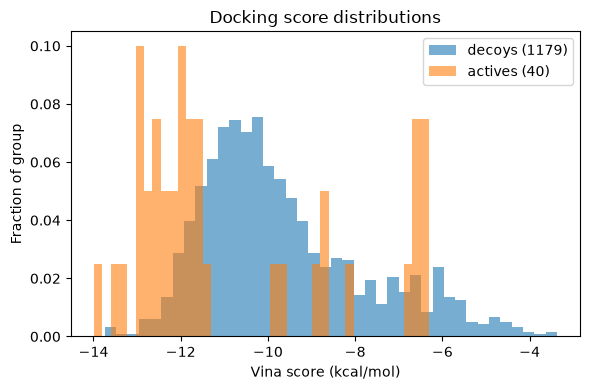

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
dec = df[df.label == 0]["score"]
act = df[df.label == 1]["score"]
plt.hist(dec, bins=40, alpha=0.6, weights=[1/len(dec)]*len(dec), label=f"decoys ({len(dec)})")
plt.hist(act, bins=40, alpha=0.6, weights=[1/len(act)]*len(act), label=f"actives ({len(act)})")
plt.xlabel("Vina score (kcal/mol)")
plt.ylabel("Fraction of group")
plt.title("Docking score distributions")
plt.legend()
plt.tight_layout()
plt.savefig("../results/score_distributions.png", dpi=150)
plt.show()

In [4]:
ranked = df.sort_values("score").reset_index(drop=True)
ranked["rank"] = ranked.index + 1
top20 = ranked.head(20)[["rank", "id", "label", "score", "heavy"]]
print(top20.to_string(index=False))
print("\nactives in top 20:", top20["label"].sum(), "of 20")

 rank           id  label   score  heavy
    1  BDB50271517      1 -13.993     40
    2 ZINC14950930      0 -13.736     39
    3 ZINC14965255      0 -13.561     39
    4 ZINC04774542      0 -13.512     46
    5 ZINC14580972      0 -13.484     37
    6 ZINC22917662      0 -13.433     36
    7  BDB50004016      1 -13.430     35
    8  BDB50032161      1 -13.310     29
    9 ZINC08926031      0 -13.166     40
   10  BDB50154767      1 -12.979     28
   11  BDB50032163      1 -12.955     28
   12  BDB50039729      1 -12.901     26
   13  BDB50271473      1 -12.888     40
   14 ZINC30512105      0 -12.885     37
   15 ZINC31039582      0 -12.879     28
   16 ZINC22772473      0 -12.871     37
   17 ZINC03253373      0 -12.858     40
   18 ZINC12572823      0 -12.790     36
   19  BDB50166995      1 -12.776     37
   20 ZINC08770129      0 -12.765     36

actives in top 20: 8 of 20


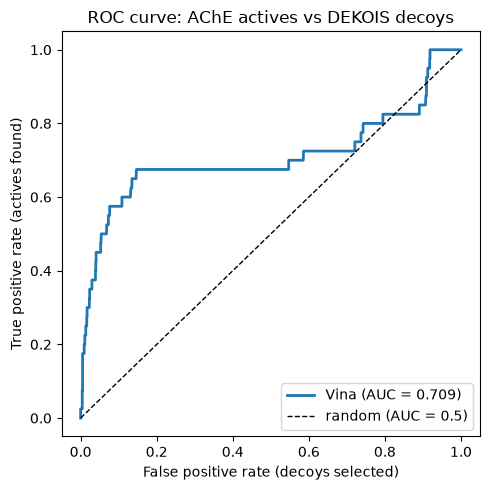

AUC = 0.709


In [5]:
from sklearn.metrics import roc_auc_score, roc_curve

y_true = df["label"]
y_score = -df["score"]
auc = roc_auc_score(y_true, y_score)
fpr, tpr, _ = roc_curve(y_true, y_score)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, lw=2, label=f"Vina (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="random (AUC = 0.5)")
plt.xlabel("False positive rate (decoys selected)")
plt.ylabel("True positive rate (actives found)")
plt.title("ROC curve: AChE actives vs DEKOIS decoys")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../results/roc_curve.png", dpi=150)
plt.show()
print("AUC =", round(auc, 3))

In [6]:
import numpy as np

rng = np.random.default_rng(42)
y_true = df["label"].values
y_score = -df["score"].values
boot = []
for _ in range(2000):
    idx = rng.choice(len(df), size=len(df), replace=True)
    if y_true[idx].sum() > 0:
        boot.append(roc_auc_score(y_true[idx], y_score[idx]))
low, high = np.percentile(boot, [2.5, 97.5])
print(f"AUC = {auc:.3f}  (95% CI {low:.3f} to {high:.3f})")

AUC = 0.709  (95% CI 0.591 to 0.818)


In [7]:
def enrichment_factor(df, fraction):
    n_top = max(1, int(round(len(df) * fraction)))
    top = df.nsmallest(n_top, "score")
    hits = top["label"].sum()
    expected = n_top * df["label"].mean()
    return n_top, hits, expected, hits / expected

for frac in [0.01, 0.05, 0.10]:
    n_top, hits, expected, ef = enrichment_factor(df, frac)
    print(f"top {frac:.0%} ({n_top} molecules): {hits} actives found, "
          f"{expected:.1f} expected by chance, EF = {ef:.1f}x")

top 1% (12 molecules): 6 actives found, 0.4 expected by chance, EF = 15.2x
top 5% (61 molecules): 15 actives found, 2.0 expected by chance, EF = 7.5x
top 10% (122 molecules): 23 actives found, 4.0 expected by chance, EF = 5.7x


In [8]:
results = pd.DataFrame([
    ["AUC", round(auc, 3)],
    ["AUC 95% CI low", round(low, 3)],
    ["AUC 95% CI high", round(high, 3)],
    ["EF 1%", 15.2],
    ["EF 5%", 7.5],
    ["EF 10%", 5.7],
    ["actives in top 20", 8],
], columns=["metric", "value"])
results.to_csv("../results/screening_metrics.csv", index=False)
ranked.drop(columns=["smiles"]).to_csv("../results/ranked_molecules.csv", index=False)
print(results.to_string(index=False))

           metric  value
              AUC  0.709
   AUC 95% CI low  0.591
  AUC 95% CI high  0.818
            EF 1% 15.200
            EF 5%  7.500
           EF 10%  5.700
actives in top 20  8.000


correlation between score and heavy atoms: -0.779


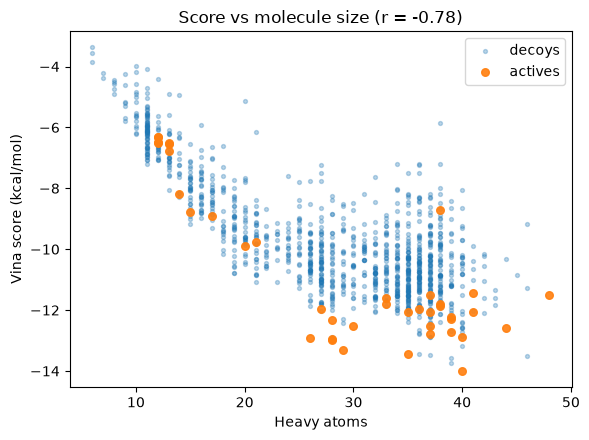

In [9]:
corr = df["score"].corr(df["heavy"])
print("correlation between score and heavy atoms:", round(corr, 3))

plt.figure(figsize=(6, 4.5))
plt.scatter(df[df.label == 0]["heavy"], df[df.label == 0]["score"], s=8, alpha=0.3, label="decoys")
plt.scatter(df[df.label == 1]["heavy"], df[df.label == 1]["score"], s=30, alpha=0.9, label="actives")
plt.xlabel("Heavy atoms")
plt.ylabel("Vina score (kcal/mol)")
plt.title(f"Score vs molecule size (r = {corr:.2f})")
plt.legend()
plt.tight_layout()
plt.savefig("../results/score_vs_size.png", dpi=150)
plt.show()

In [10]:
auc_size = roc_auc_score(df["label"], df["heavy"])
print("AUC from docking score :", round(auc, 3))
print("AUC from heavy atoms   :", round(auc_size, 3))
print("AUC from MW            :", round(roc_auc_score(df["label"], df["MW"]), 3))

AUC from docking score : 0.709
AUC from heavy atoms   : 0.576
AUC from MW            : 0.542


In [11]:
df["LE"] = df["score"] / df["heavy"]
auc_le = roc_auc_score(df["label"], -df["LE"])
print("AUC from ligand efficiency:", round(auc_le, 3))

n_top, hits, expected, ef_le = enrichment_factor(df.assign(score=df["LE"]), 0.01)
print(f"EF 1% using LE: {ef_le:.1f}x ({hits} actives in top {n_top})")

AUC from ligand efficiency: 0.572
EF 1% using LE: 0.0x (0 actives in top 12)


In [12]:
size_results = pd.DataFrame([
    ["AUC docking score", round(auc, 3)],
    ["AUC heavy atoms only", round(auc_size, 3)],
    ["AUC molecular weight only", round(roc_auc_score(df["label"], df["MW"]), 3)],
    ["AUC ligand efficiency", round(auc_le, 3)],
    ["correlation score vs heavy atoms", round(corr, 3)],
], columns=["metric", "value"])
size_results.to_csv("../results/size_bias_metrics.csv", index=False)
print(size_results.to_string(index=False))

                          metric  value
               AUC docking score  0.709
            AUC heavy atoms only  0.576
       AUC molecular weight only  0.542
           AUC ligand efficiency  0.572
correlation score vs heavy atoms -0.779
